Искусственный нейрон

Работаем в подходе черного ящика, знаем ввод, вывод, архитектуру, но что внутри, мы не знаем (для крупных моеделй)

In [57]:
from sklearn.neural_network import MLPRegressor
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split


X, y = make_regression(n_samples=2000, random_state=1)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=1)
regr = MLPRegressor(random_state=1, hidden_layer_sizes=(15, 15)).fit(X_train, y_train)
y_pred = regr.predict(X_test)

regr.score(X_test, y_test)

d:\MIREA\DPO\.venv3_11_8\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


0.9870220447908562

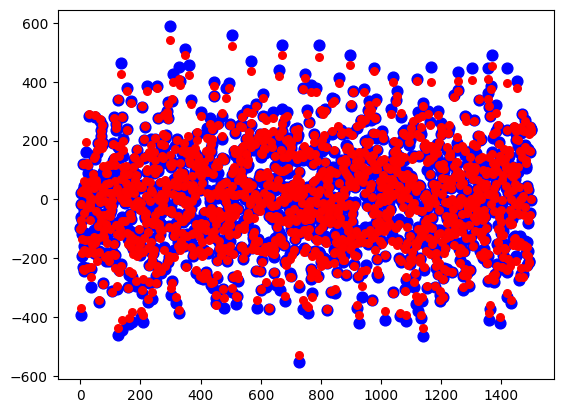

In [58]:
import matplotlib.pyplot as plt

y_pred_train = regr.predict(X_train)
plt.scatter(range(1500), y_train, c='blue', s=60)
plt.scatter(range(1500), y_pred_train, c='red', s=30)

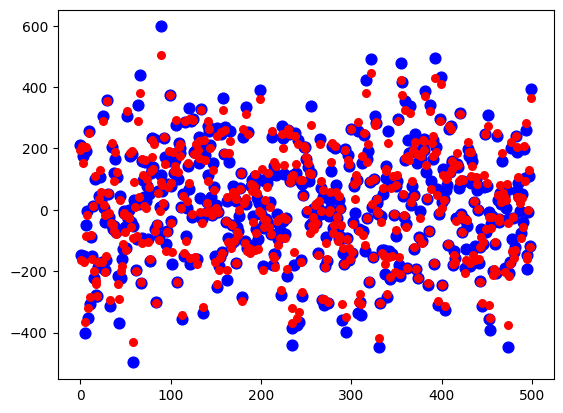

In [59]:
plt.scatter(range(500), y_test, c='blue', s=60)
plt.scatter(range(500), y_pred, c='red', s=30)

In [60]:
regr.coefs_

[array([[ 0.06963336,  0.09030959, -0.26891567, ...,  0.00400918,
          0.239038  , -0.21339732],
        [ 0.25467003, -0.02557807, -0.05644714, ..., -0.37375525,
         -0.31092727,  0.52610549],
        [-0.34419189,  0.10000757,  0.28424554, ..., -0.30183114,
          0.03330323, -0.62886679],
        ...,
        [-0.01096579,  0.19243517,  0.10555547, ..., -0.37639532,
          0.01112051, -0.57210605],
        [-0.12171083,  0.24629479, -0.42314645, ...,  0.20068872,
          0.60141364, -0.07324851],
        [-0.34630505,  0.03814853,  0.70272228, ...,  0.27216349,
          0.00385214,  0.44199255]], shape=(100, 15)),
 array([[-0.17304604,  0.38945166,  0.42098485,  1.12212628,  1.08836749,
          0.61401165,  0.16802078,  1.05979217, -0.19433255, -0.15916246,
          0.9089902 ,  0.48326245,  0.36799672,  0.51725714, -0.20296982],
        [ 1.20928138, -0.2375967 , -0.56752504, -0.16556874, -0.7350612 ,
         -0.75644798,  0.84341888, -0.65678468,  0.81625443

In [61]:
regr.intercepts_

[array([0.61015226, 1.09537208, 1.17643287, 1.00982627, 0.53115188,
        1.08031732, 1.0371689 , 0.91158636, 0.69521729, 0.75034659,
        0.75672039, 0.89702487, 1.34032489, 0.64075029, 1.17244461]),
 array([1.33237028, 0.13977441, 0.75675838, 0.68893981, 0.82662308,
        0.27511189, 1.23654077, 0.9562871 , 0.94497873, 1.4253255 ,
        0.46958592, 0.68108886, 0.54919021, 0.70394869, 0.46292372]),
 array([0.87486518])]

Глубокое обучение

Рассматриваем фреймворки автодифферецирования (изначально под тяжелые математические вычесления 20 лет назад)

Символьные вычисления и дифференцирование

In [62]:
import sympy as sp


x_s = sp.symbols('x')
y_s = sp.symbols('y')
e_s = (x_s * x_s) ** (y_s - x_s * y_s)
res = sp.diff(e_s, x_s)
print('Символьное выражение e(x, y)=', res)
print('Численные результат e(2, 3)=', res.subs([(x_s, 2.0), (y_s, 3.0)]))

Символьное выражение e(x, y)= (-y*log(x**2) + 2*(-x*y + y)/x)*(x**2)**(-x*y + y)
Численные результат e(2, 3)= -0.111857548177495


Символьные подходят для простых формул причём не всегда можно продифференцировать в простых функциях

In [63]:
!pip install torchviz

In [64]:
import torch


x = torch.tensor(2.0, requires_grad=True)
# requires_grad - ищем градиент (накапливаем его)
y = torch.tensor(3.0, requires_grad=True)

z = x * y
c = x * x
d = y - z
e = c ** d

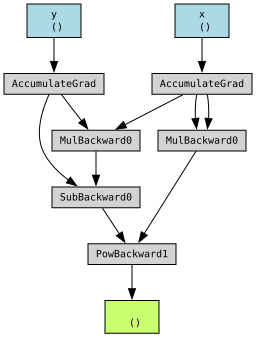

In [65]:
from torchviz import make_dot


params = dict(x=x, y=y)
make_dot(e, params=params)

In [66]:
e.backward()

Можем посмотреть производные

In [67]:
x.grad

tensor(-0.1119)

In [68]:
y.grad

tensor(-0.0217)

In [69]:
d.grad

C:\Users\nuyki\AppData\Local\Temp\ipykernel_17236\722823808.py:1: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more information. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\build\aten\src\ATen/core/TensorBody.h:494.)
  d.grad


In [70]:
a = torch.tensor([2., 3.], requires_grad=True)
b = torch.tensor([6., 4.], requires_grad=True)

Q = 3 * a ** 3 - b ** 2

In [71]:
print(Q)

tensor([-12.,  65.], grad_fn=<SubBackward0>)


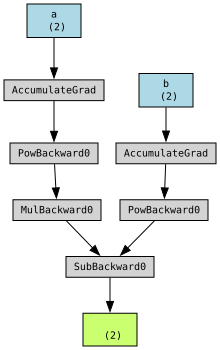

In [72]:
params = dict(a=a, b=b)
make_dot(Q, params=params)

In [73]:
external_grad = torch.tensor([1., 1.])
Q.backward(gradient=external_grad)

In [74]:
a.grad, b.grad

(tensor([36., 81.]), tensor([-12.,  -8.]))

In [75]:
print(9 * a ** 2, a.grad)
print(-2 * b, b.grad)

tensor([36., 81.], grad_fn=<MulBackward0>) tensor([36., 81.])
tensor([-12.,  -8.], grad_fn=<MulBackward0>) tensor([-12.,  -8.])


In [76]:
Q.sum().backward()
# Q.sum().backward(retain_graph=True) необходиом добавить параметр ранее

RuntimeError: Trying to backward through the graph a second time (or directly access saved tensors after they have already been freed). Saved intermediate values of the graph are freed when you call .backward() or autograd.grad(). Specify retain_graph=True if you need to backward through the graph a second time or if you need to access saved tensors after calling backward.

In [ ]:
a = torch.tensor([1.], requires_grad=True)
Q = a ** 2 - 2 * a + 5
a_grad = torch.autograd.grad(Q, a, create_graph=True)
print(a_grad)

(tensor([0.], grad_fn=<AddBackward0>),)


In [ ]:
a_grad_grad = torch.autograd.grad(a_grad, a)
print(a_grad_grad)

(tensor([2.]),)


ЗАдАчкА

In [77]:
import numpy as np


N = 201
x = np.linspace(-10, 10, N)
t = np.linspace(-10, 10, N)

shape = (len(x), len(t))
uD2x = np.zeros(shape)
uD2t = np.zeros(shape)
U = np.zeros(shape)

In [78]:
def u_fun(x, t):
    u = torch.sin(x) * torch.sin(t)
    return u

In [79]:
from tqdm import tqdm


for i in tqdm(range(shape[0])):
    for j in range(shape[1]):
        x_ = torch.tensor(x[i], requires_grad=True)
        t_ = torch.tensor(t[j], requires_grad=True)
        u_ = u_fun(x_, t_)
        Dux = torch.autograd.grad(u_, x_, create_graph=True)
        Du2x = torch.autograd.grad(Dux, x_, allow_unused=True)
        Dut = torch.autograd.grad(u_, t_, create_graph=True)
        Du2t = torch.autograd.grad(Dut, t_, allow_unused=True)
        uD2x[i][j] = Du2x[0] if Du2x[0] is not None else 0
        uD2t[i][j] = Du2t[0] if Du2t[0] is not None else 0
        U[i][j] = u_


100%|██████████| 201/201 [00:09<00:00, 21.45it/s]


In [80]:
if_equal = abs(uD2t - uD2x) < 1e-8
correct = if_equal.sum() / np.prod(shape)
print('Совпадает на ', correct)

Совпадает на  1.0


In [81]:
import matplotlib.pyplot as plt
from matplotlib import cm
from mpl_toolkits.mplot3d import Axes3D


X, T = np.meshgrid(x, t)

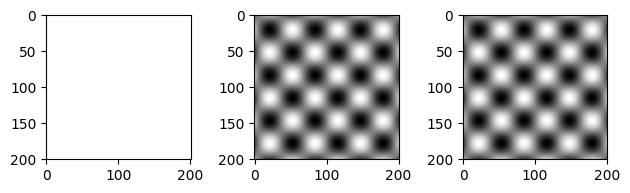

In [82]:
fig = plt.figure()

ax1 = fig.add_subplot(131)
surf = ax1.imshow(if_equal, vmin=0, vmax=1, cmap='grey')
ax2 = fig.add_subplot(132)
surf = ax2.imshow(uD2x, cmap='grey')
ax3 = fig.add_subplot(133)
surf = ax3.imshow(uD2t, cmap='grey')

plt.tight_layout(h_pad=3.)


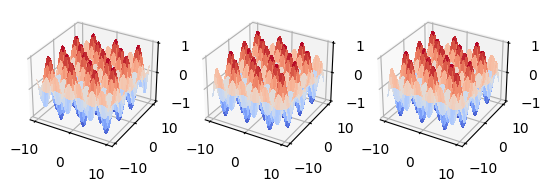

In [83]:
fig = plt.figure()
ax1 = fig.add_subplot(131, projection='3d')
surf = ax1.plot_surface(X, T, U, cmap=cm.coolwarm, linewidth=0, antialiased=False)
ax2 = fig.add_subplot(132, projection='3d')
surf = ax2.plot_surface(X, T, uD2x, cmap=cm.coolwarm, linewidth=0, antialiased=False)
ax3 = fig.add_subplot(133, projection='3d')
surf = ax3.plot_surface(X, T, uD2t, cmap=cm.coolwarm, linewidth=0, antialiased=False)

Дополнительное задание
1. Выберите датасет для MLPClassifier, снимите метрики качества классификации, сравните результаты классификации с классичесикими моделями машинного обучения
2. Проверьте, удовлетворяет ли уравнению функция и где именно
* №1 $ u(x, t) = sin(x) + sint(t) $
* №2 $ u(x, t) = x * sint(t) $
* №3 $ u(x, t) = tanh(x * t + x) * sin(3 * t) $

